# Task 5 — Trajectory Mixture และการแก้ Masked Prediction

เป้าหมายคือแก้ความแกว่งและการมองข้ามพฤติกรรมผิดปกติที่เกิดซ้ำ โดยไม่ใช้ baseline predictions เป็น labels. ทดลอง Masked v2 แล้วเปลี่ยนมาดู trajectory ของแต่ละ feature ผ่าน Gaussian mixtures. ผลทั้งหมดเป็น unlabeled diagnostics; ยังไม่มี Public score ของรุ่นใหม่.

## ผล Public ที่รายงานภายหลัง

ผู้ใช้รายงาน **0.77486** วันที่ 18 พฤศจิกายน 2026 ลดลง **0.04285** จากตัวที่ดีที่สุด **0.81771**. การทดลองนี้ไม่ช่วยเพิ่มคะแนน แม้ stability และ artificial stress tests ดีขึ้น. คะแนนนี้เป็นคะแนนรวม 5 Tasks ไม่ใช่ Task5 F3. ตารางด้านล่างเป็นผล offline ก่อนส่ง; ไม่ได้แก้โมเดลหรือ CSV หลังทราบคะแนน.

## 1. Setup

Run All โหลดผลสำเร็จแล้ว. ไม่เทรนซ้ำและไม่ส่ง Kaggle โดยอัตโนมัติ. การ fit บน Test cohort ทำตาม workflow เดิมที่ผู้ใช้ขอ แต่ข้อยกเว้นกติกา Task5 ยังไม่ได้ยืนยันจาก TA.

In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'Task5/models/trajectory_mixture_followup.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from Task5.models import trajectory_mixture_followup as mix
from Task5.models import masked_temporal_followup as old
from Task5.models import masked_temporal_repair as repaired
OUT=mix.OUT
DIAG=ROOT/'Task5/models/results/masked_repair_diagnostics_v1'
FIG=OUT/'figures'; FIG.mkdir(exist_ok=True)
RUN_TRAINING=False

## 2. เหตุผลที่เปลี่ยนแนวทาง

ตรวจค่ากลางของแต่ละ family พบ cross-domain Spearman ต่ำมาก. นี่ไม่ใช่หลักฐานว่าเป็นอิสระทุกชนิด แต่ชี้ว่าการทำนายข้ามกลุ่มอาจมีสัญญาณน้อย. ส่วน temporal autocorrelation สูง ทำให้การทำนายจากช่วงอื่นอาจมองพฤติกรรมผิดปกติที่เกิดซ้ำว่า predictable.

In [2]:
display(pd.read_parquet(DIAG/'domain_dependence.parquet'))
raw=pd.read_csv(old.RAW)
rows=[]
for f in ['login_count','device_count','currency_transfers','skill_rating','friend_adds']:
    c=raw[[f'{f}_{t}' for t in range(1,5)]].corr(method='spearman').to_numpy()
    rows.append({'family':f,'median_temporal_spearman':np.median(c[np.triu_indices(4,1)])})
display(pd.DataFrame(rows))

,domain,max_cross_domain_spearman,median_cross_domain_spearman
0,access,0.030003,0.004833
1,engagement,0.036938,0.004064
2,performance,0.036938,0.004426
3,economy,0.022005,0.004044
4,social,0.016218,0.003971


,family,median_temporal_spearman
0,login_count,0.901667
1,device_count,0.425884
2,currency_transfers,0.910698
3,skill_rating,0.977083
4,friend_adds,0.885508


## 3. รุ่นที่ทดลอง

**Masked v2:** ซ่อนทั้ง domain ตลอด 4 ช่วงเวลา, mask scheduling สมดุล, row-normalized pinball, ประเมิน validation ทุก mask, MLP 256→128 ไม่มี dropout. ปรับคะแนน mask ด้วย empirical tail แล้วเฉลี่ยสองค่าที่สูงสุด. ยังแกว่ง จึงไม่เลือกเป็น submission.

**Trajectory Mixture:** 27 behavioral families แต่ละตัวใช้ joint trajectory 4 ช่วงเวลา และ geographic steps 3 ค่าเป็นอีก family. asinh สำหรับพฤติกรรม, log1p(km) สำหรับระยะทาง. 3 folds × 3 training subsamples. GaussianMixture full covariance เลือก 1–4 components ด้วย BIC บน training ของ seed แรกในแต่ละ fold แล้วใช้ K นั้นใน bags อื่น. รวม 252 saved models.

ให้คะแนนจาก `−log(sum(component_weight × chi-square_survival(Mahalanobis_distance²)))` จึงตอบสนองทั้งกลุ่มที่มีมวลน้อยและจุดที่ห่างจากกลุ่ม ผ่านกลไกเดียว. ไม่ใช่ calibrated p-value หรือ fraud probability. ใช้ mean สอง family scores ที่สูงสุด แล้ว median ข้าม bags. เลือก top 2,046 เป็นงบเทียบ ไม่ใช่ prevalence estimate.

Fit แต่ละ family ด้วย training rows ที่ครบทุกช่วง; inference ใช้ Gaussian marginal บนมิติที่มีข้อมูลจริง. ทั้ง family หายให้ score=0 ไม่ถือ missing อย่างเดียวเป็น anomaly. ไม่ใช้ absolute location, security flags, account ID หรือผลโมเดลเดิม.

In [3]:
display(mix.CONFIG)
if RUN_TRAINING: mix.run()
settings=json.loads((OUT/'settings.json').read_text())
assert settings['raw_sha256']==old.sha(old.RAW)
assert settings['source_sha256']==old.sha(mix.__file__)
fit=pd.read_parquet(OUT/'fit_diagnostics.parquet')
display(fit.groupby('components').size().rename('saved_models').to_frame())
assert len(fit)==252 and fit.converged.all()

{'seeds': [173, 271, 389],
 'folds': 3,
 'split_seed': 619,
 'outer_train_fraction': 0.8,
 'component_grid': [1, 2, 3, 4],
 'covariance': 'full',
 'reg_covar': 0.001,
 'max_iter': 150,
 'score': 'negative log of mixture-weighted chi-square survival mass',
 'aggregation': 'mean largest two family scores; median across three bags',
 'budget': 2046,
 'threads': 4,
 'rule_exception': 'unverified; user requested previous Test-cohort fitting workflow'}

,saved_models
components,
3,27
4,225


## 4. ความเสถียรและเทียบกับ 0.81771

ตรวจสูตรหลังสร้าง predictions แล้ว ไม่ปรับ weights/threshold ให้เหมือน baseline. Stability และ overlap ไม่ใช่ accuracy.

,method,seed_Jaccard,baseline_alert_overlap,common_alerts,added,removed,all_row_agreement
0,Masked v1,0.467900,0.512219,1048,998,998,0.922902
1,Masked v2,0.525616,0.473118,968,1078,1078,0.916721
2,Trajectory mixture,0.905652,0.753177,1541,505,505,0.960987


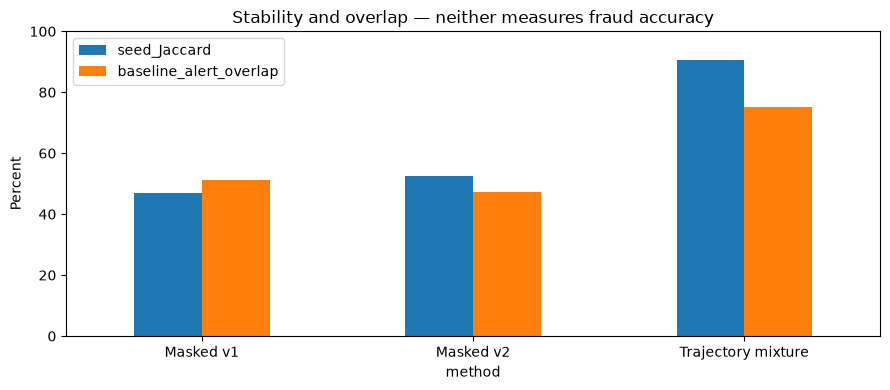

,reference,public_overall_score,rows,new_alerts,reference_alerts,common_alerts,added,removed,all_row_agreement,new_alert_overlap,reference_alert_retention,alert_jaccard
0,density_auto_v1,0.81771,25889,2046,2046,1541,505,505,0.960987,0.753177,0.753177,0.604077
1,rank_fusion95_5_v1,0.80678,25889,2046,2046,1541,505,505,0.960987,0.753177,0.753177,0.604077
2,multiscale_representation_v1,0.73801,25889,2046,2046,1210,836,836,0.935417,0.591398,0.591398,0.419847
3,behavior_blocks5_v1,0.79798,25889,2046,2046,1547,499,499,0.961451,0.756109,0.756109,0.607859
4,tail_engineered_v20,0.75893,25889,2046,6531,1737,309,4794,0.802889,0.848974,0.265962,0.253947


In [4]:
records=[]
for name,folder in [('Masked v1',old.OUT),('Masked v2',repaired.OUT),('Trajectory mixture',OUT)]:
    report=json.loads((folder/'report.json').read_text());ref=report['comparisons'][0]
    records.append({'method':name,'seed_Jaccard':np.mean([r['jaccard'] for r in report['stability']]),'baseline_alert_overlap':ref['new_alert_overlap'],'common_alerts':ref['common_alerts'],'added':ref['added'],'removed':ref['removed'],'all_row_agreement':ref['all_row_agreement']})
summary=pd.DataFrame(records); display(summary)
ax=summary.set_index('method')[['seed_Jaccard','baseline_alert_overlap']].mul(100).plot.bar(figsize=(9,4),rot=0)
ax.set(ylabel='Percent',ylim=(0,100),title='Stability and overlap — neither measures fraud accuracy')
plt.tight_layout();plt.savefig(FIG/'repair_comparison.png',dpi=150);plt.show()
display(pd.read_parquet(OUT/'reference_comparison.parquet').drop(columns='sha256'))

## 5. Stress tests แบบจับคู่

ใช้ seed173 ของแต่ละ fold เลือก 600 outer-heldout accounts ต่อ fold. แก้ข้อมูลจำลอง 5 แบบ: spike ชั่วคราว, activity shift ทุกช่วง, รูปแบบสม่ำเสมอทุกช่วง, skill/social shift, เปลี่ยนพิกัดจากบัญชีอื่นในข้อมูลเดิม. ใช้ cutoff จาก original outer-heldout scores ที่สัดส่วน 2,046/25,889.

Original accounts ไม่มี labels และอาจเป็น anomaly อยู่แล้ว. AUC ด้านล่างแยกข้อมูลเดิมกับข้อมูลที่เราแก้ ไม่ใช่ fraud AUC/F3. Perturbations ถูกออกแบบทดสอบ failure modes จึงไม่แทน distribution การโกงจริง และไม่ได้ใช้เลือก threshold.

,method,scenario,original_vs_perturbed_auc,original_alert_fraction,perturbed_alert_fraction,paired_score_increase
0,masked_v1,geographic_switch,0.692570,0.091667,0.239444,0.801667
1,masked_v1,persistent_activity_shift,0.786908,0.091667,0.352778,0.929444
2,masked_v1,persistent_regular_pattern,0.818077,0.091667,0.403889,0.912778
3,masked_v1,skill_social_change,0.960277,0.091667,0.966111,0.987778
4,masked_v1,temporary_activity_spike,0.782650,0.091667,0.373333,0.940000
5,masked_v2,geographic_switch,0.862743,0.083889,0.623333,0.949444
6,masked_v2,persistent_activity_shift,0.974770,0.083889,0.951667,0.992778
7,masked_v2,persistent_regular_pattern,0.994701,0.083889,0.992778,0.996111
8,masked_v2,skill_social_change,0.995743,0.083889,0.985556,0.997778
9,masked_v2,temporary_activity_spike,0.926491,0.083889,0.669444,0.994444


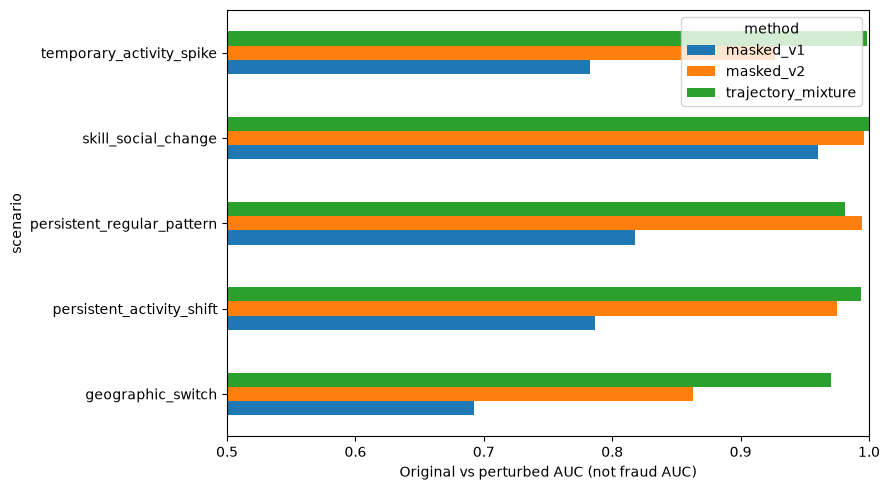

In [5]:
stress=pd.read_parquet(DIAG/'synthetic_stress_summary.parquet')
display(stress[['method','scenario','original_vs_perturbed_auc','original_alert_fraction','perturbed_alert_fraction','paired_score_increase']])
table=stress.pivot(index='scenario',columns='method',values='original_vs_perturbed_auc')
ax=table.plot.barh(figsize=(9,5));ax.set(xlabel='Original vs perturbed AUC (not fraud AUC)',xlim=(.5,1))
plt.tight_layout();plt.savefig(FIG/'stress_auc.png',dpi=150);plt.show()

## 6. บัญชีเข้า–ออกและหลักฐานราย feature

คำว่า added/removed เทียบกับ baseline เท่านั้น ไม่ใช่ true/false positive. Dominant family คือ family score สูงสุดของ median scores; คะแนนรวมมาจาก median ของ top-two aggregate แต่ละ bag จึงอย่าตีความตารางนี้เป็น additive attribution.

In [6]:
diff=pd.read_parquet(OUT/'baseline_row_comparison.parquet')
display(diff.groupby('change').size().rename('accounts').to_frame())
display(pd.read_parquet(OUT/'dominant_family_by_change.parquet'))
for change in ['added','removed']:
    sample=diff[diff.change.eq(change)].sort_values('score',ascending=False).head(10).copy()
    sample['largest_family']=sample[mix.FAMILIES].idxmax(axis=1)
    display(sample[['id','player_id','score','prediction','baseline_prediction','largest_family']])

,accounts
change,
added,505
normal_both,23338
removed,505
retained,1541


,row_0,added,normal_both,removed,retained
0,accuracy_mean,2,838,5,13
1,accuracy_std,9,1646,28,0
2,activity_level,0,631,65,195
3,communication_frequency,5,1184,54,145
4,currency_transfers,2,582,5,47
5,device_count,0,40,0,0
6,friend_adds,0,493,4,23
7,friend_removes,2,811,5,30
8,geo_steps,205,967,17,32
9,guild_changes,0,88,1,231


,id,player_id,score,prediction,baseline_prediction,largest_family
24950,ANS24951,P001489,10.203391,1,0,geo_steps
6816,ANS06817,P021920,8.910722,1,0,session_duration_mean
12489,ANS12490,P015469,8.783574,1,0,geo_steps
10992,ANS10993,P017545,8.482603,1,0,geo_steps
6832,ANS06833,P007085,8.359529,1,0,geo_steps
12483,ANS12484,P020448,8.258202,1,0,session_duration_mean
25022,ANS25023,P009920,8.135727,1,0,geo_steps
11515,ANS11516,P025636,7.983541,1,0,currency_transfers
2748,ANS02749,P018684,7.912695,1,0,geo_steps
17937,ANS17938,P012410,7.818057,1,0,location_changes


,id,player_id,score,prediction,baseline_prediction,largest_family
7039,ANS07040,P008427,4.259812,0,1,skill_rating
12863,ANS12864,P015532,4.259004,0,1,activity_level
10989,ANS10990,P001059,4.258800,0,1,activity_level
19281,ANS19282,P006618,4.252251,0,1,activity_level
6712,ANS06713,P001788,4.244877,0,1,communication_frequency
10438,ANS10439,P016562,4.244008,0,1,activity_level
7366,ANS07367,P018504,4.241549,0,1,activity_level
422,ANS00423,P011521,4.237892,0,1,communication_frequency
20107,ANS20108,P011210,4.235957,0,1,communication_frequency
22695,ANS22696,P021982,4.230206,0,1,kda_std


## 7. ตรวจ saved models และ submission

252 mixtures และ 9 Masked v2 checkpoints โหลดกลับมา replay held-out scores แล้ว. ตรวจ train/test row disjoint, fitted preprocessing, prediction aggregation และ raw/reference hashes. CSV ใหม่เปลี่ยนเฉพาะ Task5 จากไฟล์ที่ได้ 0.81771.

In [7]:
verify=json.loads((OUT/'verification.json').read_text())
assert verify['all_replays_passed'] and verify['all_selected_models_converged']
manifest=json.loads((OUT/'export_manifest.json').read_text());candidate=manifest['candidates'][0]
with open(manifest['source'],newline='') as f: src=list(csv.reader(f))
with open(candidate['output'],newline='') as f: dst=list(csv.reader(f))
assert len(src)==len(dst)==25890
assert all(a[:5]==b[:5] for a,b in zip(src,dst))
assert [int(r[5]) for r in dst[1:]]==candidate['task5']
assert sum(int(r[5]) for r in dst[1:])==2046
display({'models_replayed':len(verify['models']),'rows':len(dst)-1,'Task1_to_4_preserved':True,'output':candidate['output'],'submitted':False})

{'models_replayed': 252,
 'rows': 25889,
 'Task1_to_4_preserved': True,
 'output': '/Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/submission/kaggle_t12345_t1_slow800_bagging_v4_t3_conditional_quantile_v1_t4_resnet18_cosine18_tta_v1_t5_trajectory_mixture_v1.csv',
 'submitted': False}

## 8. ข้อสรุปและข้อจำกัด

Trajectory Mixture แก้ความแกว่งและตอบสนอง stress tests ได้ดีกว่า Masked v1; เป็นตัวทดลองที่น่าสนใจกว่าในรอบนี้. ยังไม่พิสูจน์ว่าคะแนน Kaggle จะชนะ 0.81771. กลุ่มเล็กอาจเป็นผู้เล่นปกติ, Gaussian assumptions อาจไม่เหมาะกับ count variables, complete-case training อาจมี missingness bias. 2,046 เป็น fixed budget และไม่มี labels สำหรับหาค่าเหมาะสม. ไม่ได้ผสมสาม detectors เดิมหรือใช้ผลเดิมฝึก. กฎเรื่อง Test fitting ยังต้องยืนยันกับ TA.